# Microstructure correlation from a real neutron spin echo experiment

## Problem and provenance
This notebook actively reconstructs all40 published polystyrene suspension depolarisation measurements acquired on2014-07-10. The nominal particle diameter is approximately2micrometers; it is not treated as exact truth. The unknowns are particle radius and volume fraction in the released monodisperse sphere model. The output is a model-inferred three-dimensional radial autocovariance, not individual particle locations.

The physical basis is the conventional **linear** SESANS formalism explicitly described in Kadletz, Bouwman and Pappas2022, *Radial spin echo small-angle neutron scattering method: concept and performance*, JAC55,1072–1084, DOI10.1107/S1600576722007245, section1.2. We do not substitute its radial-instrument experiment for these linear-SESANS data. Its full published text and equations were independently reviewed. The historical Andersson2008 analysis paper was bibliographically located and previewed; full access was unavailable, so it is not claimed as read. Exact-source Sasmodels/Bumps inversion supplies an independent standard-method reference, not microscopic truth.

In [1]:
from pathlib import Path
import sys,json,time,importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.physics_model import *
from src.solvers import reconstruct
from src.visualization import comparisons
data=load_observations()
print('Complete real observations:',len(data['spin_echo_length']))
print('NumPy:',np.__version__)
print('Wavelength (Angstrom):',np.unique(data['wavelength']))


Complete real observations: 40
NumPy: 2.4.6
Wavelength (Angstrom): [2.11]


## Physical forward model
Let $R$ be sphere radius in Angstrom and $\phi$ particle volume fraction, constrained below one half to resolve complementary-phase ambiguity. With sphere volume $V=4\pi R^3/3$ and known SLD difference $\Delta\rho=(1.41-2.70)10^{-6}$ Angstrom inverse squared, the macroscopic cross section is

$$I(q)=10^8(\Delta\rho)^2\phi(1-\phi)V\left[3\frac{\sin(qR)-qR\cos(qR)}{(qR)^3}\right]^2.$$

The normalized sphere amplitude tends to one at $q=0$; the local implementation uses the upstream stable four-term series below $|qR|=0.1$. Here q is inverse Angstrom, I is inverse cm and $10^8$ is the length unit conversion. There is no additional structure factor.

For spin echo length z, ordinary Bessel function $J_0$, sample thickness t and neutron wavelength $\lambda$,

$$D(z)=\frac{\ln(P/P_0)}{t\lambda^2}=G(z)-G(0),\qquad G(z)=\frac{1}{2\pi}\int qI(q)J_0(qz)\,dq.$$

D is the published signed reduced depolarisation in Angstrom inverse squared cm inverse; the source curves are not raw polarization. This relation follows from the two-dimensional Fourier projection in the full primary paper's linear-SESANS discussion. It includes multiple-scattering attenuation through the exponential polarization relation; we fit the already reduced log quantity.

## Discretization, correction and inverse updates
Use the exact released finite logarithmic quadrature: qmin=$0.1(2\pi)/(40z_{\max})$, qmax=$2\pi/(z_1-z_0)$, spacing ratio1.0003, upper endpoint excluded. Backward q differences give the integration weights, with the first difference equal to the second. The Bessel matrix H and its zero-length row H0 give D=H.T@I-H0@I. All40 signed observations and original errors are retained. Reported length errors remain available but the selected model fits nominal coordinates without extra smearing.

An upstream dimensional discrepancy was investigated: a Q cutoff is passed into an angle comparison. In this bound dataset every integration node is below **both** the physical angular limit and the source's numeric comparison. The local implementation uses angle units correctly; frozen matrix/forward parity and the independent maximum-angle check below prove that no value changes here. Behavior on arbitrary other acquisition grids is not claimed identical.

Minimize half the sum of squared standardized (model-minus-data) residuals. Original Bumps projected bounds are retained: radius100–100000Angstrom and fraction0.001–0.5. The source's13 zero uniform/fixed-prior residuals and its stray-distance penalty are implemented explicitly. MINPACK LM uses the original initial vector(10000,0.0855), ftol=xtol=1.5e-8, epsfcn=1e-8, and600 maximum evaluations. No regularizer, domain solver or cached reconstruction enters the cleaned implementation.

In [2]:
q,H,H0=hankel(data)
print('Integration q samples:',len(q),'Q range:',q[0],q[-1])
angle=np.arcsin(q.max()*data['wavelength'].max()/(2*np.pi))
print('Largest encoded angle / physical acceptance (radian):',angle,THETA_MAX)
assert angle<THETA_MAX
fresh,info=reconstruct(data)
np.savez(ROOT/'output/reconstruction.npz',**fresh)
print('ACTIVELY RECONSTRUCTED:',json.dumps(info,indent=2))
with np.load(ROOT/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as a:upstream={k:a[k].copy() for k in a.files}


Integration q samples: 32216 Q range: 3.407441217368915e-07 0.0053584345796121756
Largest encoded angle / physical acceptance (radian): 0.0017994540208390447 0.0168
ACTIVELY RECONSTRUCTED: {
  "seconds": 0.044009000062942505,
  "nfev": 13,
  "success": true,
  "message": "Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000",
  "chisqr": 39.98566457122466
}


## From projected scattering to radial microstructure
The three-dimensional overlap of two spheres separated by r is $\gamma(r)=1-3r/(4R)+r^3/(16R^3)$ for $0\le r\le2R$, zero beyond the diameter. The reconstructed indicator covariance is $C(r)=\phi(1-\phi)\gamma(r)$, a dimensionless material phase correlation. It is evaluated at r=0,100,...,50000Angstrom.

This is distinguished from the measured projected G(z): direct equality of the two would be an incorrect inverse. From $r^2=x^2+s^2$ the geometrical projection is $2\int_x^\infty\gamma(r)r/\sqrt{r^2-x^2}\,dr$; we derive this relation independently rather than rely on ambiguous text extraction of the paper's image-based Abel equation. The shipped calculation uses the Bessel/Hankel form. Independent zero-q/Guinier/total-scattering and sphere-overlap checks support the mathematical interpretation.

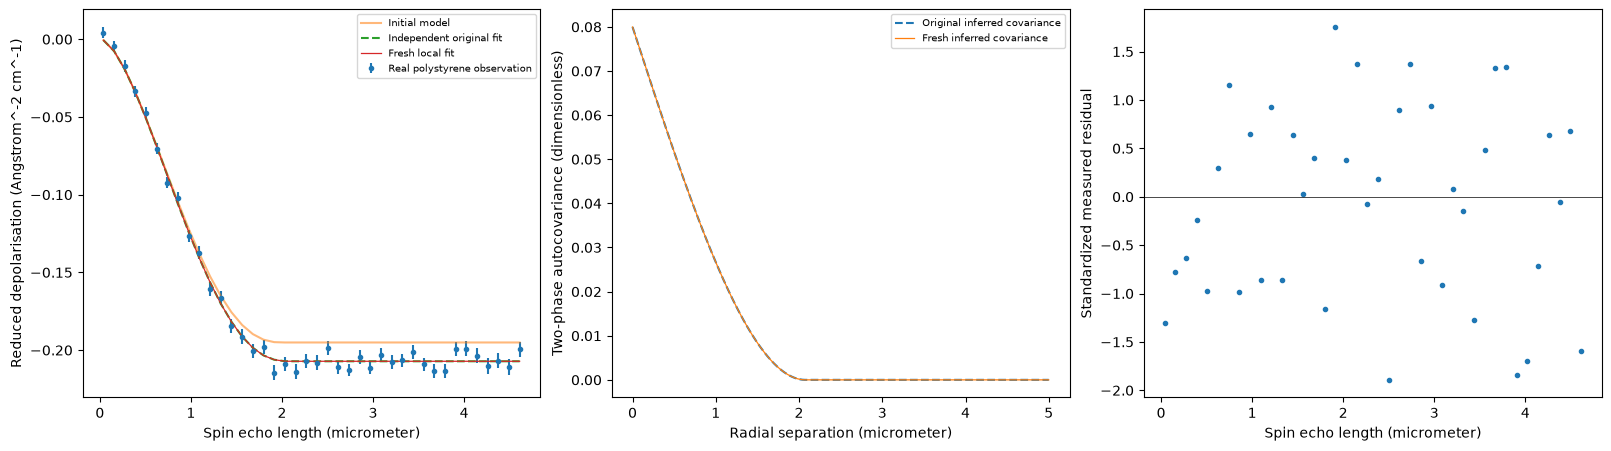

Parameter            Unit                  Initial  Original fit   Fresh local
sphere radius        Angstrom                10000     10381.863     10381.863
volume fraction      dimensionless          0.0855   0.087668954   0.087668954
Fresh inferred diameter (micrometer): 2.076372615385176


In [3]:
fig=comparisons(data,fresh,upstream)
fig.savefig(ROOT/'output/review.png',dpi=150)
plt.show()
print(f"{'Parameter':20s} {'Unit':15s} {'Initial':>13s} {'Original fit':>13s} {'Fresh local':>13s}")
for name,unit,i,u,v in zip(['sphere radius','volume fraction'],['Angstrom','dimensionless'],INITIAL,upstream['parameters'][0],fresh['parameters'][0]):
    print(f'{name:20s} {unit:15s} {i:13.8g} {u:13.8g} {v:13.8g}')
print('Fresh inferred diameter (micrometer):',2*fresh['parameters'][0,0]/10000)


## Metrics and comparison provenance
All scientific curves above are measured or actually computed. The initial model, independently executed original source fit, fresh local fit and both inferred autocovariances are identified separately. No true particle map exists for evaluation. Historical sample labels and paper plots are not represented as fresh metrics.

Profile NRMSE is RMS covariance difference divided by original-fit covariance dynamic range. Parameter errors are normalized by10000Angstrom and0.1volume fraction. Chi squared sums40 measured standardized residuals. Independent changed-init original runs differed by profile NRMSE9.9379247e-8 and maximum parameter error4.2919005e-7; boundaries2e-5,1e-5,40.4 were frozen before the local extraction was judged.

In [4]:
spec=importlib.util.spec_from_file_location('judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,code=judge.evaluate(ROOT/'output/reconstruction.npz')
print(json.dumps(report,indent=2));assert code==0
print('Reduced measurement chi squared (40-2 DOF):',report['metrics']['chisqr']/38)
print('Active reconstruction time (s):',info['seconds'])


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "profile_nrmse": 1.4167998283200556e-13,
    "parameter_error": 5.243028233792302e-13,
    "chisqr": 39.98566457122466
  },
  "thresholds": {
    "profile_nrmse": {
      "comparison": "<=",
      "boundary": 2e-05
    },
    "parameter_error": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "chisqr": {
      "comparison": "<=",
      "boundary": 40.4
    }
  },
  "errors": []
}
Reduced measurement chi squared (40-2 DOF): 1.0522543308217016
Active reconstruction time (s): 0.044009000062942505


## Conclusion and limits
The active cleaned sphere/Hankel inverse agrees with the independently executed original-source standard method. The real observation fit has reduced chi squared approximately1.0523, and the inferred diameter is near the sample's nominal2micrometers. This does not independently prove an exact radius, monodispersity, absence of interparticle correlations, or the unique true microscopic covariance. Both uncertainties and the selected uniform-sphere model limit interpretation. The small physical-angle correction is transparent and numerically inactive on the bound data, not an unreported general change to the original code.